<a href="https://colab.research.google.com/github/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting/blob/afomia/Forecasting_Project_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NYC Motor Vehicle Collisions: Exploratory Data Analysis and Problem Definition

**Group repository:** https://github.com/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting

This notebook explores the cleaned crash-count series, defines the forecasting problem and sets out the validation strategy agreed by the group. The series are produced by the data cleaning notebook and loaded from the `data/` folder of the repository.

## 1. Setup and load the data

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

# Folder in the group repository that holds the cleaned series
DATA_FOLDER = (
    "https://raw.githubusercontent.com/Advanced-Forecasting-Project/NYC-Car-Crashes-Forecasting/refs/heads/main/data/"
)

# Display settings
pd.set_option("display.max_columns", 30)
plt.rcParams["figure.figsize"] = (12, 4)

# Load the three series
daily = pd.read_csv(DATA_FOLDER + "nyc_daily_crash_counts.csv", index_col=0, parse_dates=True)["crash_count"]
weekly = pd.read_csv(DATA_FOLDER + "nyc_weekly_crash_counts.csv", index_col=0, parse_dates=True)["crash_count"]
monthly = pd.read_csv(DATA_FOLDER + "nyc_monthly_crash_counts.csv", index_col=0, parse_dates=True)["crash_count"]

for name, series in [("Daily", daily), ("Weekly", weekly), ("Monthly", monthly)]:
    print(f"{name}: {len(series):,} values | {series.index.min().date()} to {series.index.max().date()} | total {series.sum():,}")

daily.head()

Daily: 4,062 values | 2012-07-01 to 2023-08-14 | total 2,016,512
Weekly: 580 values | 2012-07-08 to 2023-08-13 | total 2,015,737
Monthly: 133 values | 2012-07-01 to 2023-07-01 | total 2,012,979


,crash_count
date,
2012-07-01,538
2012-07-02,563
2012-07-03,664
2012-07-04,431
2012-07-05,591


## 2. Overview of the series

The same 11 years of crashes are available at three frequencies. This section compares their size and level, and shows how aggregating from days to weeks to months changes what is visible.

         observations       start         end   mean   std   min    max
series                                                                 
Daily            4062  2012-07-01  2023-08-14    496   169    94   1160
Weekly            580  2012-07-08  2023-08-13   3475  1076   826   5347
Monthly           133  2012-07-01  2023-07-01  15135  4603  4127  21336


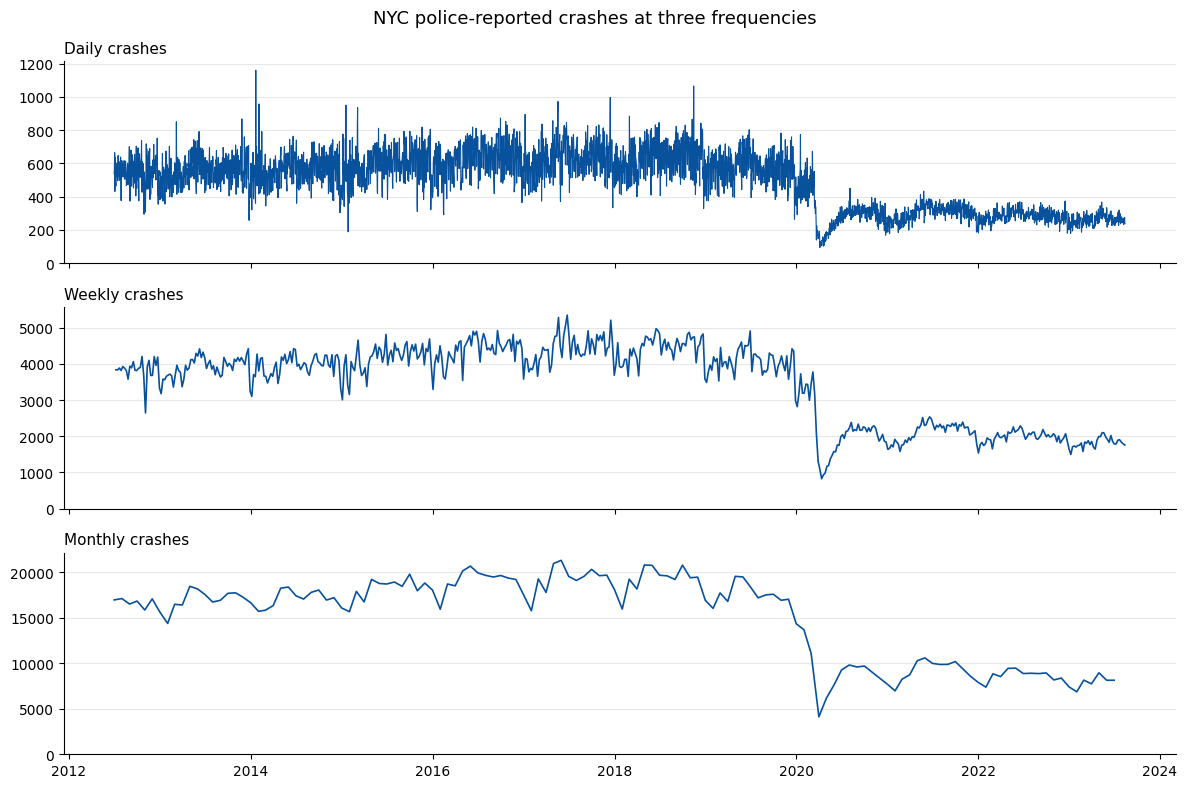

In [ ]:
series_by_freq = {"Daily": daily, "Weekly": weekly, "Monthly": monthly}

# One row of summary figures per series
rows = []
for name, s in series_by_freq.items():
    rows.append({
        "series": name,
        "observations": len(s),
        "start": s.index.min().date(),
        "end": s.index.max().date(),
        "mean": round(s.mean()),
        "std": round(s.std()),
        "min": s.min(),
        "max": s.max(),
    })
overview = pd.DataFrame(rows).set_index("series")
print(overview)

# One panel per series, sharing the same time axis
fig, axes = plt.subplots(3, 1, figsize=(12, 8), sharex=True)
for ax, (name, s) in zip(axes, series_by_freq.items()):
    ax.plot(s.index, s, color="#08519C", linewidth=0.8 if name == "Daily" else 1.2)
    ax.set_title(f"{name} crashes", loc="left", fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.3)
    ax.set_ylim(bottom=0)
fig.suptitle("NYC police-reported crashes at three frequencies", fontsize=13)
fig.tight_layout()
plt.show()

- **The daily series has by far the most data**: 4,062 observations, against 580 weekly and 133 monthly over the same period. This matters for models that need many observations, especially if only post-2020 data is used.
- **All three show the same structural break in spring 2020**, when the level roughly halves and does not recover. Because the series spans both periods, the overall mean (496 crashes a day) and standard deviation describe neither period well.
- **Aggregating removes noise but also detail.** The daily series is dominated by day-to-day variation and single-day spikes (the largest is 1,160 crashes). The weekly series smooths most of this but still shows unusual weeks. The monthly series shows a clear yearly pattern, with a dip near the start of each year.
- **Monthly totals depend on month length.** February has 28 or 29 days and other months 30 or 31, so February's total is around 10% lower even if the daily rate is unchanged. Part of the early-year dip in the monthly series may be this calendar effect rather than fewer crashes. Section 4 compares months using the **average per day** to separate the two.

## 3. Trend and the COVID-19 structural break

Section 2 showed a sharp, lasting drop in spring 2020. This section describes the long-term direction of the series, measures the level of each year, pinpoints when the drop happened, and compares the trend before and after it. The results decide how much of the history should be used for training.

### 3.0 Long-term direction

A 30-day rolling mean smooths out day-to-day noise and the weekly pattern, so the underlying direction becomes visible. The dashed line marks 22 March 2020, when New York State's "PAUSE" executive order took effect, closing all non-essential businesses (New York State Governor's Office, 2020).

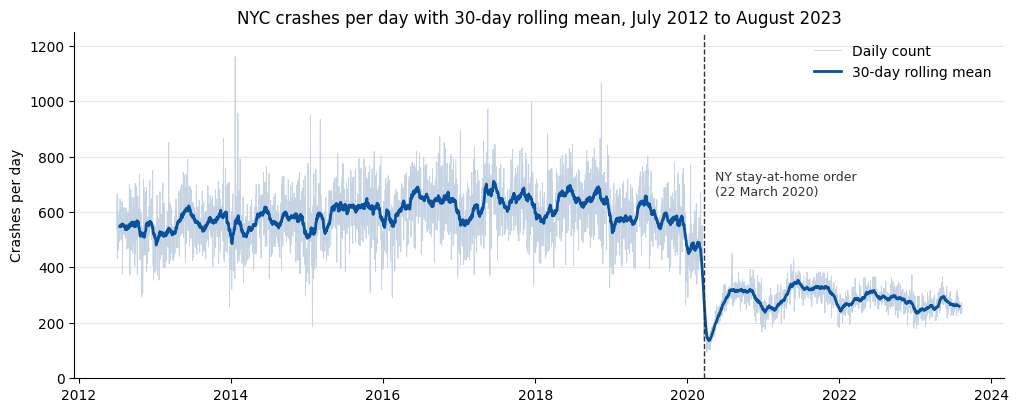

Highest 30-day mean: 2017-06-16 - 711 crashes per day
Lowest 30-day mean in spring 2020: 2020-04-13 - 137 crashes per day


In [ ]:
LOCKDOWN_START = pd.Timestamp("2020-03-22")

rolling_30 = daily.rolling(30, center=True).mean()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(daily.index, daily, color="#C6D3E3", linewidth=0.6, label="Daily count")
ax.plot(rolling_30.index, rolling_30, color="#08519C", linewidth=2, label="30-day rolling mean")
ax.axvline(LOCKDOWN_START, color="#333333", linestyle="--", linewidth=1)
ax.annotate("NY stay-at-home order\n(22 March 2020)", (LOCKDOWN_START, 700), xytext=(8, 0),
            textcoords="offset points", fontsize=9, color="#333333", va="center")
ax.set_ylim(0, 1250)
ax.set_title("NYC crashes per day with 30-day rolling mean, July 2012 to August 2023")
ax.set_ylabel("Crashes per day")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")
plt.show()

# Highest point of the rolling mean, and its lowest point during the lockdown
print("Highest 30-day mean:", rolling_30.idxmax().date(), "-", round(rolling_30.max()), "crashes per day")
lockdown_low = rolling_30["2020-03-01":"2020-06-30"]
print("Lowest 30-day mean in spring 2020:", lockdown_low.idxmin().date(), "-", round(lockdown_low.min()), "crashes per day")

**What this shows**

The series has **two distinct periods separated by a level shift**:

- **July 2012 to early 2020: slow growth, then a turn.** The rolling mean rose gradually from about 550 crashes a day in 2012 to a peak of 711 in mid-June 2017, stayed high through 2018, and started falling during 2019, before COVID.
- **Spring 2020: a sudden level shift.** Within a few weeks of the stay-at-home order, the rolling mean fell to 137 crashes a day in mid-April, less than a quarter of its early-2020 level.
- **Mid-2020 onward: a new, lower level with a slow decline.** The series recovered to around 300 a day by summer 2020 but never returned to the earlier level, and has drifted down since, to about 250 by 2023.

The rolling mean also rises and falls within each year, which points to yearly seasonality (Section 4). The following subsections measure the yearly levels (3.1), date the break precisely (3.2) and compare the trend in each period (3.3).

       mean  count
date              
2012  546.0    184
2013  558.0    365
2014  564.0    365
2015  595.0    365
2016  627.0    366
2017  632.0    365
2018  634.0    365
2019  579.0    365
2020  308.0    366
2021  303.0    365
2022  284.0    365
2023  261.0    226


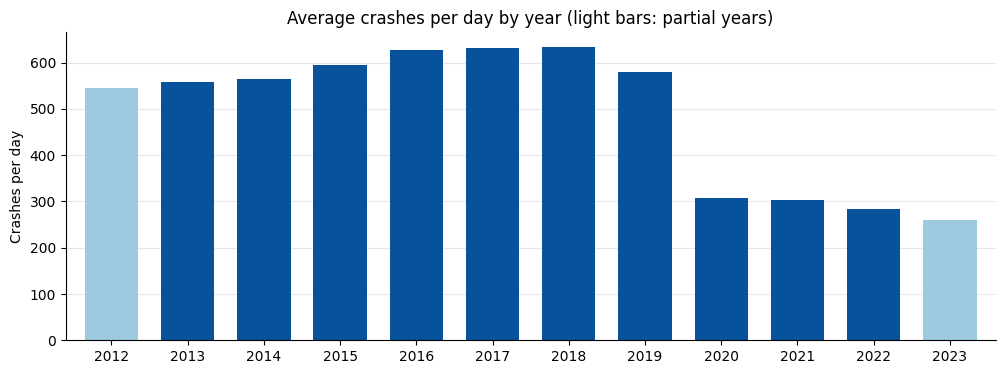

In [ ]:
yearly = daily.groupby(daily.index.year).agg(["mean", "count"])
yearly["mean"] = yearly["mean"].round(0)
print(yearly)

# Partial years (fewer than 365 days of data) get a lighter colour
colors = ["#9ECAE1" if days < 365 else "#08519C" for days in yearly["count"]]

ax = yearly["mean"].plot(kind="bar", color=colors, width=0.7)
ax.set_title("Average crashes per day by year (light bars: partial years)")
ax.set_xlabel("")
ax.set_ylabel("Crashes per day")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

Crashes rose steadily from 2013 (558 a day) to a peak in 2016–2018 (about 630), then fell to 579 in 2019, **before COVID-19**. In 2020 the average halved to 308, and it has kept falling since: 303 in 2021, 284 in 2022 and 261 in the first part of 2023. The 2020 figure mixes the normal first weeks of the year with the lockdown, so it describes neither period.

Average crashes per day, by week (week ending on the date shown):
date
2020-03-01    494.0
2020-03-08    539.0
2020-03-15    454.0
2020-03-22    296.0
2020-03-29    186.0
2020-04-05    155.0
2020-04-12    118.0
2020-04-19    133.0
2020-04-26    140.0
Freq: W-SUN, Name: crash_count, dtype: float64


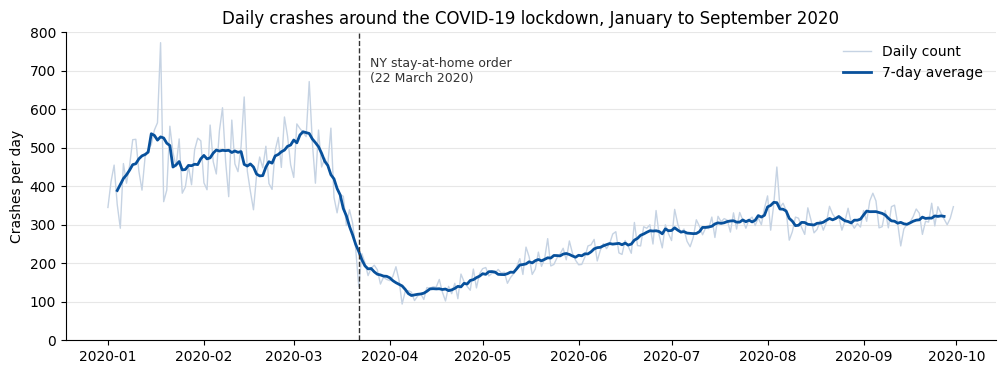

In [ ]:

# Weekly averages around the break, to date it precisely
print("Average crashes per day, by week (week ending on the date shown):")
print(daily["2020-02-24":"2020-04-26"].resample("W").mean().round(0))

window = daily["2020-01-01":"2020-09-30"]

fig, ax = plt.subplots()
ax.plot(window.index, window, color="#C6D3E3", linewidth=1, label="Daily count")
ax.plot(window.index, window.rolling(7, center=True).mean(), color="#08519C", linewidth=2, label="7-day average")
ax.axvline(LOCKDOWN_START, color="#333333", linestyle="--", linewidth=1)
ax.annotate("NY stay-at-home order\n(22 March 2020)", (LOCKDOWN_START, 700), xytext=(8, 0),
            textcoords="offset points", fontsize=9, color="#333333", va="center")
ax.set_ylim(0, 800)
ax.set_title("Daily crashes around the COVID-19 lockdown, January to September 2020")
ax.set_ylabel("Crashes per day")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")
plt.show()

The drop **began in the week before the stay-at-home order**: daily crashes averaged 539 in the week ending 8 March, 454 the following week, and 296 in the week ending 22 March, as people had already begun staying home. The lowest point came in the week ending 12 April (118 a day, about a fifth of the early-March level). Crashes then recovered gradually until around **July 2020**, when they levelled off at roughly 300 a day, well below the pre-COVID level.

So the break has three phases: a sudden fall over about three weeks, a partial recovery from mid-April to July, and a new, lower level from July 2020 onward.

### 3.3 Level and trend before and after the break

In [ ]:
import numpy as np

# Average level in each period, compared with 2017–2019
periods = {
    "Before COVID (2017–2019)": ("2017-01-01", "2019-12-31"),
    "Lockdown (22 Mar – 31 May 2020)": ("2020-03-22", "2020-05-31"),
    "After COVID (Jul 2020 – Aug 2023)": ("2020-07-01", "2023-08-14"),
}
pre_covid_level = daily["2017-01-01":"2019-12-31"].mean()

rows = []
for name, (start, end) in periods.items():
    level = daily[start:end].mean()
    rows.append({
        "period": name,
        "days": len(daily[start:end]),
        "mean_per_day": round(level),
        "pct_of_pre_covid": round(level / pre_covid_level * 100),
    })
print(pd.DataFrame(rows).set_index("period"))

# Straight-line trend within each stable period
print()
regimes = {"Jul 2012 – Dec 2019": ("2012-07-01", "2019-12-31"),
           "Jul 2020 – Aug 2023": ("2020-07-01", "2023-08-14")}
for name, (start, end) in regimes.items():
    s = daily[start:end]
    years = (s.index - s.index[0]).days / 365.25
    slope, intercept = np.polyfit(years, s.values, deg=1)
    print(f"{name}: trend {slope:+.1f} crashes per day per year ({slope / s.mean():+.1%} of the period average)")

                                   days  mean_per_day  pct_of_pre_covid
period                                                                 
Before COVID (2017–2019)           1095           615               100
Lockdown (22 Mar – 31 May 2020)      71           170                28
After COVID (Jul 2020 – Aug 2023)  1140           289                47

Jul 2012 – Dec 2019: trend +10.3 crashes per day per year (+1.7% of the period average)
Jul 2020 – Aug 2023: trend -13.8 crashes per day per year (-4.8% of the period average)


- **The new level is less than half the old one.** From July 2020 to August 2023, NYC averaged 289 crashes a day, 47% of the 2017–2019 level (615). During the lockdown itself it fell to 28%.
- **The trend reversed direction.** Before COVID, crashes rose by about 10 a day per year (+1.7% a year). After July 2020, they fall by about 14 a day per year (−4.8% a year). The two periods behave like different series.

**Implications for modelling**

1. **A model trained on the full 2012–2023 history would be misled twice**: by a level that is twice too high, and by an upward trend that no longer holds. Both would push forecasts well above the current level.
2. **The two options for the group are:**
   - **Train on July 2020 onward only.** This is simple and matches current behaviour. It leaves about 1,140 daily observations (just over three years), enough for daily and weekly models but only about 37 monthly values.
   - **Keep the full history and add a COVID indicator** (a variable equal to 1 from the break onward), so the model can learn the level shift. This keeps more data for estimating seasonality, but assumes the seasonal pattern was the same before and after COVID, which Section 4 checks.
3. **The lockdown and recovery months (mid-March to June 2020) are unusual even within the post-COVID period** and should be excluded from training or marked separately, whichever option is chosen.

## 4. Seasonality

A forecasting model needs to know which repeating patterns to capture. This section checks two: the **day-of-week** pattern and the **time-of-year** pattern. Each is compared before and after COVID-19, because if a pattern changed, data from before 2020 can't be used to estimate it for the present.

To compare the shapes despite the halved level, each pattern is shown as a percentage of its own period's average.

### 4.1 Day of week

           Before COVID (2017–2019)  After COVID (Jul 2020 – Aug 2023)
date                                                                  
Monday                        100.5                               98.0
Tuesday                       103.5                               99.4
Wednesday                     102.8                              100.0
Thursday                      106.8                              101.9
Friday                        112.0                              109.3
Saturday                       93.0                               99.7
Sunday                         81.5                               91.8

Gap between highest and lowest day (percentage points):
Before COVID (2017–2019)             30.5
After COVID (Jul 2020 – Aug 2023)    17.5
dtype: float64


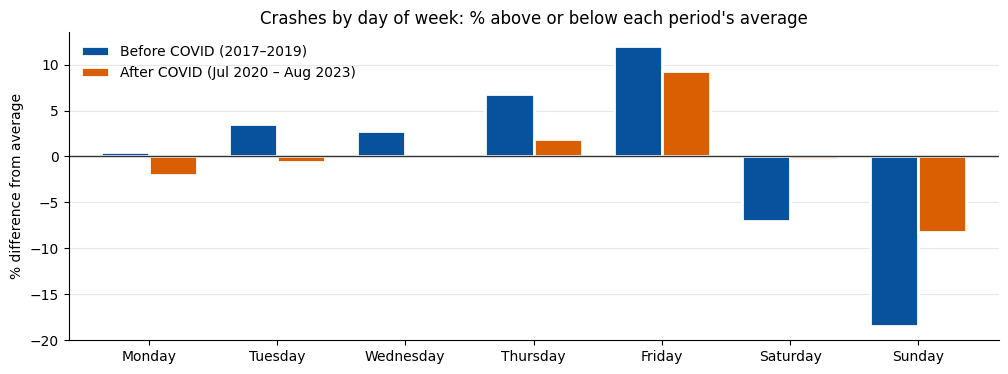

In [ ]:
PRE_COVID = daily["2017-01-01":"2019-12-31"]
POST_COVID = daily["2020-07-01":"2023-08-14"]
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

def weekday_profile(s):
    """Average crashes on each weekday, as % of the series' overall average."""
    return (s.groupby(s.index.day_name()).mean() / s.mean() * 100).reindex(WEEKDAYS).round(1)

weekday = pd.DataFrame({
    "Before COVID (2017–2019)": weekday_profile(PRE_COVID),
    "After COVID (Jul 2020 – Aug 2023)": weekday_profile(POST_COVID),
})
print(weekday)
print("\nGap between highest and lowest day (percentage points):")
print((weekday.max() - weekday.min()).round(1))

# Bars show how far each weekday is above or below its period's average
ax = (weekday - 100).plot(kind="bar", color=["#08519C", "#D95F02"], width=0.75, edgecolor="white", linewidth=2)
ax.axhline(0, color="#333333", linewidth=1)
ax.set_title("Crashes by day of week: % above or below each period's average")
ax.set_xlabel("")
ax.set_ylabel("% difference from average")
ax.tick_params(axis="x", rotation=0)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
plt.show()

**Friday remains the busiest day and Sunday the quietest.** Before COVID, Friday sat 12% above average and Sunday 18% below.

**After COVID, the weekly pattern flattened significantly.** The gap between the busiest and quietest days dropped from 30.5% to 17.5%. Monday through Thursday fell closer to average, while weekends rose. Saturday moved from 7% below average to roughly average, and Sunday climbed from 18% to 8% below. Less weekday commuting is a likely factor, though the data alone cannot confirm the cause.

**Implication:** Any daily model needs to account for these day-of-week swings. However, because the pattern shifted, applying one fixed weekly profile across the full history will misrepresent current trends. To stay accurate, either train the model strictly on post-COVID data or allow the weekly pattern to differ between the two periods.

### 4.2 Time of year

Here each day is compared with the average of **its own calendar year**, so that the different levels of different years (and the downward trend) don't distort the pattern. Using averages per day also removes the month-length effect noted in Section 2. Only complete calendar years are used: 2013–2019 before COVID, and 2021–2022 after (2020 is broken by the lockdown and 2023 is incomplete).

      Before COVID (2013–2019)  After COVID (2021–2022)
date                                                   
Jan                       91.6                     86.0
Feb                       93.1                     87.5
Mar                       96.4                     94.2
Apr                       96.2                     98.3
May                      105.9                    108.4
Jun                      109.5                    113.9
Jul                      101.2                    103.6
Aug                       98.8                    103.2
Sep                      102.7                    106.5
Oct                      103.1                    105.1
Nov                      101.9                     99.5
Dec                       99.2                     93.3

Gap between highest and lowest month (percentage points):
Before COVID (2013–2019)    17.9
After COVID (2021–2022)     27.9
dtype: float64

Correlation between the two patterns: 0.94


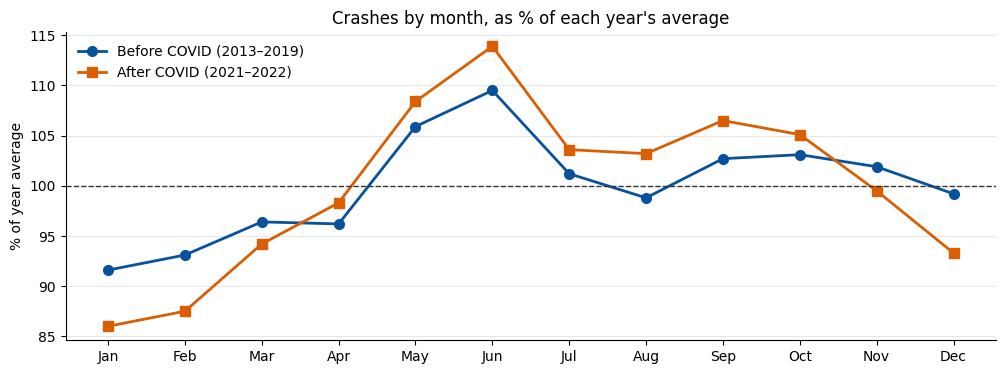

In [ ]:
def month_profile(s):
    """Average crashes in each calendar month, as % of the average of their own year."""
    relative = s / s.groupby(s.index.year).transform("mean") * 100
    return relative.groupby(relative.index.month).mean().round(1)

month = pd.DataFrame({
    "Before COVID (2013–2019)": month_profile(daily["2013-01-01":"2019-12-31"]),
    "After COVID (2021–2022)": month_profile(daily["2021-01-01":"2022-12-31"]),
})
month.index = pd.to_datetime(month.index, format="%m").strftime("%b")   # 1 → Jan, 2 → Feb ...
print(month)
print("\nGap between highest and lowest month (percentage points):")
print((month.max() - month.min()).round(1))
print("\nCorrelation between the two patterns:", round(month.iloc[:, 0].corr(month.iloc[:, 1]), 2))

fig, ax = plt.subplots()
for column, color, marker in zip(month.columns, ["#08519C", "#D95F02"], ["o", "s"]):
    ax.plot(month.index, month[column], color=color, linewidth=2, marker=marker, markersize=7, label=column)
ax.axhline(100, color="#333333", linewidth=1, linestyle="--")
ax.set_title("Crashes by month, as % of each year's average")
ax.set_ylabel("% of year average")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper left")
plt.show()

- **The yearly pattern has the same shape before and after COVID** (correlation 0.94): crashes are lowest in January and February, rise through spring to a peak in **June**, dip in July–August, rise again slightly in September–October, and fall towards the end of the year.
- **But it is stronger after COVID.** The gap between the highest and lowest month grew from 17.9% to 27.9%: January is now 14% below the yearly average (8% before) and June 14% above (10% before).
- **Caution:** the post-COVID pattern rests on only two full years, so it's much less certain than the pre-COVID one. The downward trend within each year may also slightly exaggerate the low December figure.

**Implications**

1. **A yearly pattern clearly exists**, so models should include one: for example month indicators, or smooth yearly terms (Fourier terms) for daily data. A model that only captures the weekly pattern would systematically over-forecast in winter and under-forecast in early summer.
2. **The shape is stable but the strength changed.** Pre-COVID data could help estimate *when* the highs and lows happen, but not *how large* they are now. Combined with the change in the weekly pattern (4.1), this supports **training on post-COVID data**. The cost is that the yearly pattern is then estimated from only about three cycles.

### 4.3 STL decomposition

STL (Seasonal-Trend decomposition using LOESS) splits a series into three parts:
- **trend**: the slow-moving level,
- **seasonal**: a pattern that repeats with a fixed period,
- **remainder**: whatever is left, i.e. noise and unusual events.

STL handles one seasonal period at a time, and this series has two (weekly and yearly), so two decompositions are run:
- **4.3a** uses **monthly averages per day** over the full history with a period of 12, to show the yearly pattern and the COVID break. Averages per day are used instead of monthly totals, to remove the month-length effect (Section 2).
- **4.3b** uses **daily counts** from July 2020 onward with a period of 7, to show the weekly pattern in the candidate training window.

Both are run on the **log** of the series. STL adds its parts together, so on the log scale the seasonal part becomes a percentage effect, which suits a series whose variation grows with its level (Section 7). `robust=True` stops unusual values (storms, the lockdown) from distorting the trend and seasonal parts.

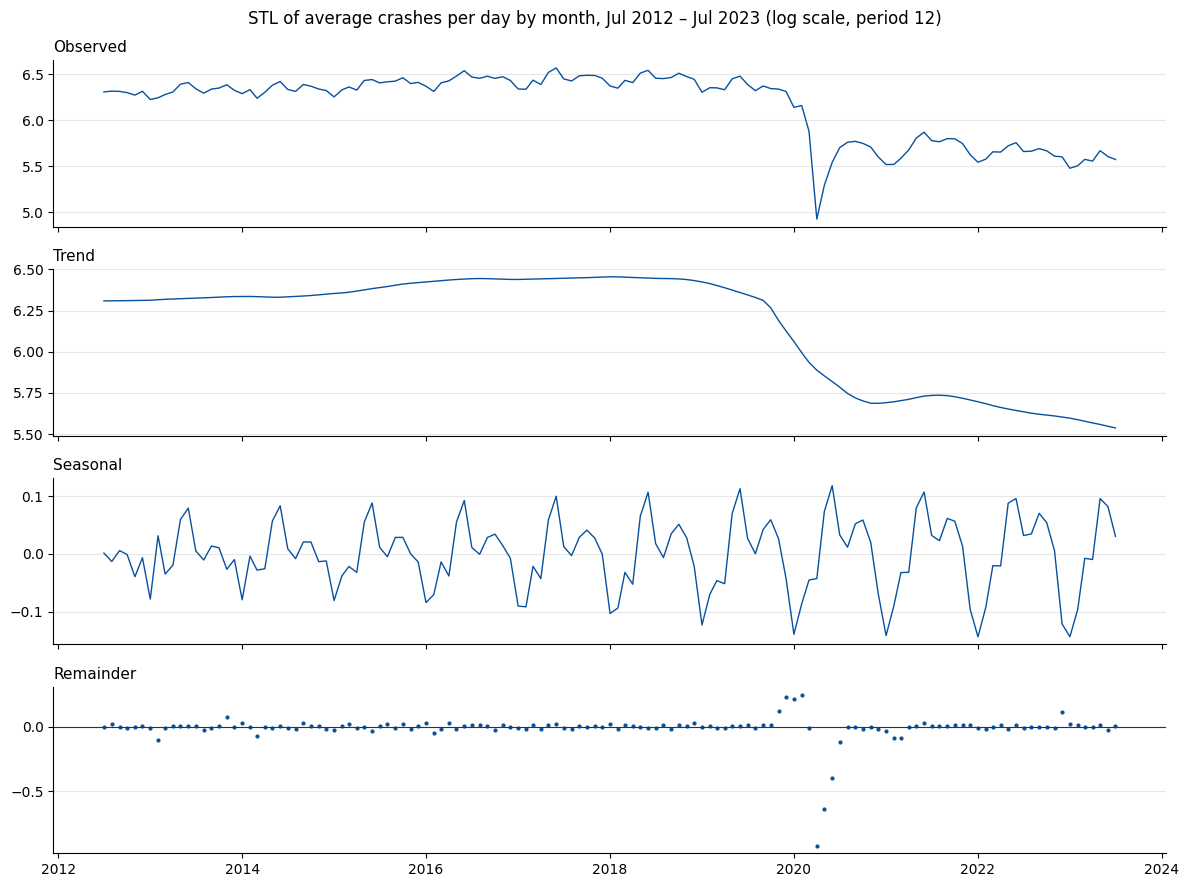

Average seasonal effect by month (%):
date
Jan   -10.4
Feb    -6.2
Mar    -2.7
Apr    -3.3
May     7.1
Jun    10.2
Jul     1.9
Aug     0.2
Sep     3.6
Oct     3.8
Nov     0.5
Dec    -3.6
Name: season, dtype: float64

Largest remainders (log scale):
date
2020-04-01    0.92
2020-05-01    0.64
2020-06-01    0.40
2020-02-01    0.25
2019-12-01    0.23
Name: resid, dtype: float64


In [ ]:
from statsmodels.tsa.seasonal import STL

def plot_stl(result, title):
    """Plot the observed series and the three STL components in four stacked panels."""
    parts = {"Observed": result.observed, "Trend": result.trend,
             "Seasonal": result.seasonal, "Remainder": result.resid}
    fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
    for ax, (name, values) in zip(axes, parts.items()):
        if name == "Remainder":
            ax.scatter(values.index, values, s=4, color="#08519C")
            ax.axhline(0, color="#333333", linewidth=0.8)
        else:
            ax.plot(values.index, values, color="#08519C", linewidth=1)
        ax.set_title(name, loc="left", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.3)
    fig.suptitle(title, fontsize=12)
    fig.tight_layout()
    plt.show()

# 4.3a: monthly average per day, full history (complete months only), yearly period
monthly_avg = daily[:"2023-07-31"].resample("MS").mean()
stl_monthly = STL(np.log(monthly_avg), period=12, trend=13, robust=True).fit()
plot_stl(stl_monthly, "STL of average crashes per day by month, Jul 2012 – Jul 2023 (log scale, period 12)")

monthly_effect = (np.exp(stl_monthly.seasonal.groupby(stl_monthly.seasonal.index.month).mean()) - 1) * 100
monthly_effect.index = pd.to_datetime(monthly_effect.index, format="%m").strftime("%b")
print("Average seasonal effect by month (%):")
print(monthly_effect.round(1))
print("\nLargest remainders (log scale):")
print(stl_monthly.resid.abs().sort_values(ascending=False).head(5).round(2))

**What this shows (4.3a, monthly, full history)**

- **Trend:** level and slightly rising until 2018, easing in 2019, a steep fall through 2020, then a slow decline. This matches the rolling mean in Section 3.0.
- **Seasonal:** a stable yearly shape, with January about 10% below trend and June about 10% above it, a smaller rise in September–October, and lower values in December. The **size of the wave grows over time**, which agrees with Section 4.2: the yearly pattern is stronger after COVID.
- **Remainder:** close to zero for almost the whole period, which means trend plus seasonality explain the monthly series well. The exception is 2020: the remainder is positive in early 2020 and strongly negative in April–June.

**Why the remainder is so large in 2020:** STL assumes the trend changes **smoothly**. A sudden level shift like the lockdown can't be represented that way, so the trend line starts falling too early (hence positive remainders in early 2020) and falls too slowly (hence large negative remainders in spring 2020). This is a limitation of the method, and it shows that the COVID break has to be handled explicitly, by cutting off the earlier data or by adding an indicator, rather than left for a smooth trend to absorb.

#### 4.3b Weekly pattern, daily data from July 2020

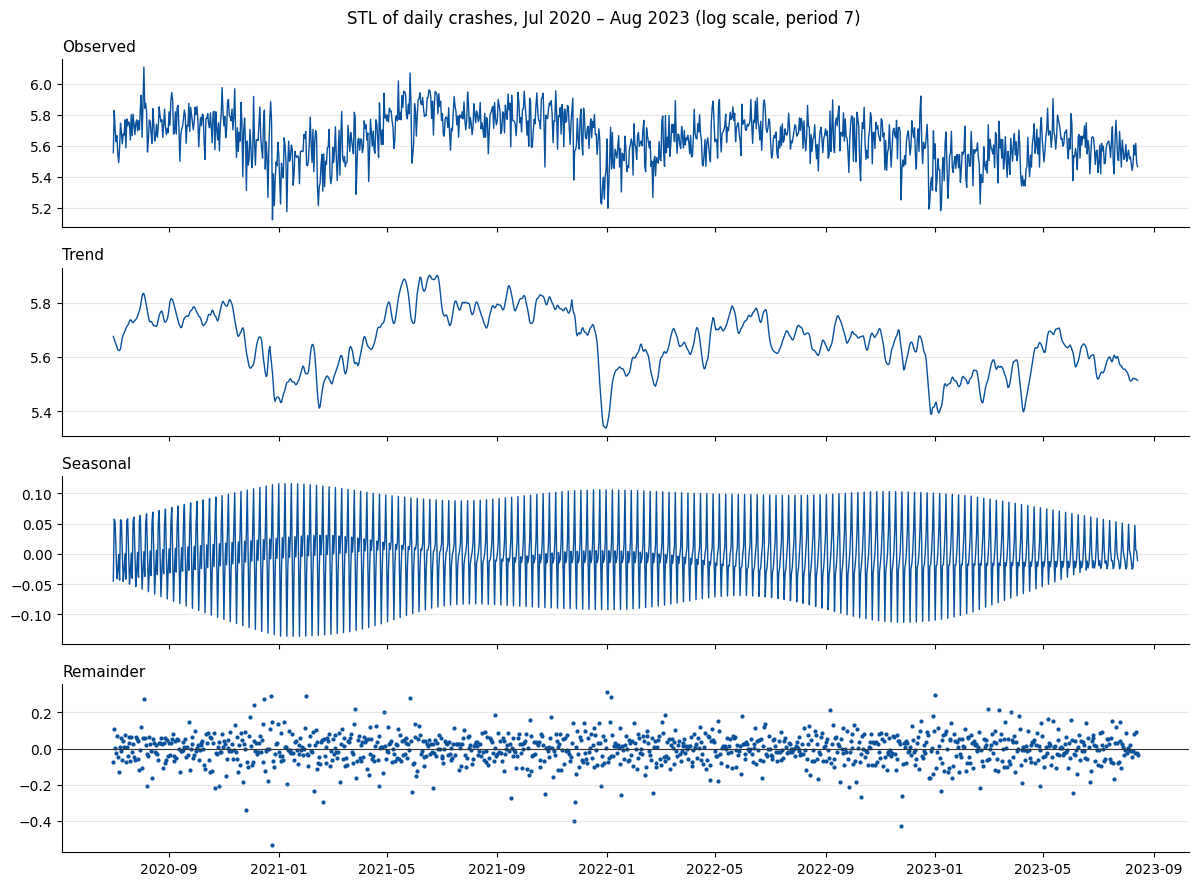

Average seasonal effect by weekday (%):
date
Monday      -1.9
Tuesday     -0.6
Wednesday   -0.6
Thursday     2.7
Friday       9.7
Saturday    -0.1
Sunday      -8.3
Name: season, dtype: float64


In [ ]:
stl_daily = STL(np.log(POST_COVID), period=7, seasonal=53, robust=True).fit()
plot_stl(stl_daily, "STL of daily crashes, Jul 2020 – Aug 2023 (log scale, period 7)")

weekday_effect = (np.exp(stl_daily.seasonal.groupby(stl_daily.seasonal.index.day_name()).mean()) - 1) * 100
print("Average seasonal effect by weekday (%):")
print(weekday_effect.reindex(WEEKDAYS).round(1))

**What this shows (4.3b, daily, post-COVID)**

- **Seasonal:** a stable weekly pattern with Friday about 10% above trend and Sunday about 8% below, the other days close to average. These figures agree with the simple averages in Section 4.1, which confirms the weekly pattern is robust to the method used.
- **Trend:** with only the weekly pattern removed, the trend still contains the **yearly** pattern: it dips each winter (most clearly around each New Year) and peaks in late spring and summer. A daily model therefore needs both a weekly and a yearly component.
- **Remainder:** mostly small and evenly scattered around zero, with no visible pattern left, so trend plus weekly seasonality capture the main structure. The few large remainders are single unusual days, which are examined in Section 5.2.

**Implication:** the decomposition confirms the structure a daily model has to capture: a slowly changing level, a weekly pattern (Friday high, Sunday low) and a yearly pattern (winter low, early summer high). It also shows that the COVID break can't be treated as part of a smooth trend.

## 5. Unusual days

This section looks at days that don't follow the normal pattern: public holidays (5.1), other unusual days such as storms and the COVID-19 lockdown (5.2), and changes in how crashes were recorded (5.3).

### 5.1 Public holidays

The cleaning notebook found that several of the most unusual low days were public holidays. This subsection measures the effect of each US federal holiday on crashes, to decide whether a holiday indicator should be added to the models.

Each holiday is compared with a **baseline**: the median of the same weekday one and two weeks before and after. This removes the day-of-week and time-of-year patterns, leaving the effect of the holiday itself. The lockdown and recovery months (March to June 2020) are excluded, because their baseline is distorted by the sudden drop.

Holidays in the data: 114
                                       mean   min    max  count
holiday                                                        
Christmas Day                          57.0  42.0   76.0     11
Thanksgiving Day                       65.0  58.0   71.0     11
Washington's Birthday                  70.0  47.0   86.0     11
Memorial Day                           71.0  51.0   91.0     10
Independence Day                       73.0  55.0  102.0     12
Labor Day                              80.0  62.0   98.0     11
Martin Luther King Jr. Day             81.0  66.0   96.0     11
Columbus Day                           81.0  64.0  107.0     11
New Year's Day                         87.0  60.0  144.0     11
Veterans Day                           93.0  71.0  129.0     11
Juneteenth National Independence Day  102.0  92.0  108.0      3

Normal days: 90% fall between 82% and 120% of their baseline


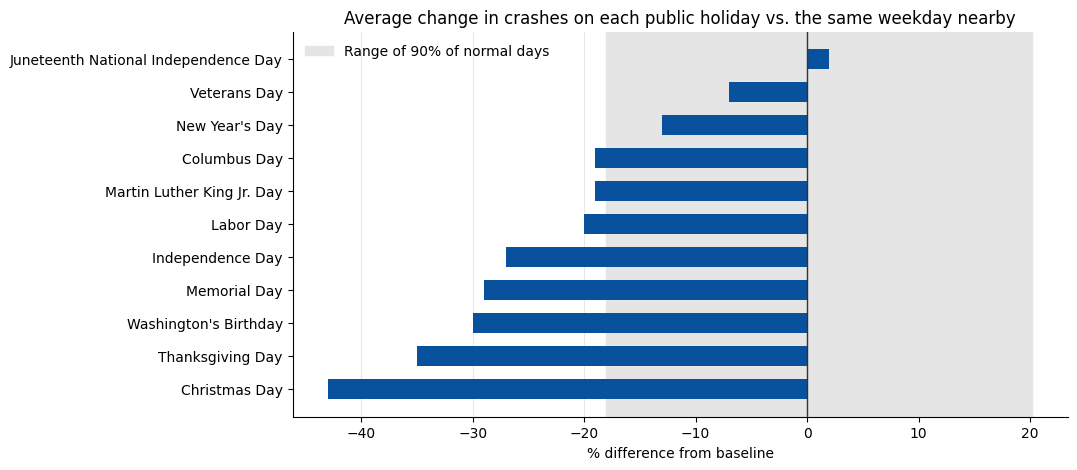

In [ ]:
import holidays   # if this fails in Colab, run:  !pip install holidays

# Actual US federal holiday dates (observed=False keeps 25 December even when the day off moves to a Monday)
us_holidays = holidays.US(years=range(2012, 2024), observed=False)
holiday_dates = pd.Series({pd.Timestamp(date): name for date, name in us_holidays.items()}).sort_index()
holiday_dates = holiday_dates[daily.index.min():daily.index.max()]
print("Holidays in the data:", len(holiday_dates))

# Baseline: median of the same weekday 1 and 2 weeks before and after
same_weekday_nearby = pd.concat([daily.shift(k) for k in [14, 7, -7, -14]], axis=1)
baseline = same_weekday_nearby.median(axis=1)
pct_of_baseline = daily / baseline * 100

# Leave out March–June 2020
in_lockdown = (daily.index >= "2020-03-01") & (daily.index < "2020-07-01")
pct_of_baseline = pct_of_baseline[~in_lockdown]

# Effect of each holiday, averaged over the years
holiday_effect = pd.DataFrame({
    "holiday": holiday_dates,
    "pct_of_baseline": pct_of_baseline.reindex(holiday_dates.index),
}).dropna()
summary = (holiday_effect.groupby("holiday")["pct_of_baseline"]
           .agg(["mean", "min", "max", "count"]).round(0).sort_values("mean"))
print(summary)

# How much do ordinary days vary around the same baseline?
normal_days = pct_of_baseline.drop(holiday_dates.index, errors="ignore")
low, high = normal_days.quantile([0.05, 0.95])
print(f"\nNormal days: 90% fall between {low:.0f}% and {high:.0f}% of their baseline")

# Chart: average change per holiday, against the range of normal days
change = summary["mean"] - 100
fig, ax = plt.subplots(figsize=(10, 5))
ax.axvspan(low - 100, high - 100, color="#E5E5E5", label="Range of 90% of normal days")
ax.barh(change.index, change, color="#08519C", height=0.6)
ax.axvline(0, color="#333333", linewidth=1)
ax.set_title("Average change in crashes on each public holiday vs. the same weekday nearby")
ax.set_xlabel("% difference from baseline")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="upper left")
plt.show()

**What this shows**

- **Most holidays have clearly fewer crashes.** Nine of the eleven federal holidays are below their baseline on average.
- **Five holidays have an effect larger than normal day-to-day variation**, falling outside the range of 90% of ordinary days (82–120%): **Christmas Day** (43% fewer crashes than a comparable day), **Thanksgiving** (35% fewer), **Washington's Birthday** (30%), **Memorial Day** (29%) and **Independence Day** (27%).
- **Thanksgiving and Christmas are also the most consistent**: Thanksgiving was between 58% and 71% of its baseline in every year, so the effect is reliable rather than driven by one unusual year.
- **Labor Day, Martin Luther King Jr. Day and Columbus Day** show smaller drops of around 20%, at the edge of the normal range.
- **New Year's Day and Veterans Day** show little average effect and vary widely (New Year's Day ranged from 60% to 144%), so their effect is unreliable.
- **Juneteenth** has only three observations, since it became a federal holiday in 2021, and shows no clear effect.

**Implications**

1. **A holiday indicator is worth adding to daily models.** A model without one would over-forecast crashes on Christmas and Thanksgiving by roughly a third to two-fifths.
2. **Holidays are known in advance**, so unlike weather they can be used as predictors for any forecast horizon without needing to be forecast themselves.
3. **The effects differ a lot between holidays**, so a single "is a holiday" variable would average them out. Separate indicators for the major holidays (Christmas, Thanksgiving, Washington's Birthday, Memorial Day, Independence Day) would capture them better, at the cost of more parameters estimated from only about ten observations each.
4. **For weekly or monthly forecasts the effect is diluted**: one holiday is one day out of seven (or about thirty), so it matters much less at those frequencies.

### 5.2 Other unusual days: storms, the lockdown and unexplained days

To find unusual days systematically, an STL decomposition is run on the **full** daily series (log scale, weekly period). Each day's **remainder** is the difference between what happened and what the trend and weekly pattern would predict. A day is flagged as unusual if its remainder is more than **4 robust standard deviations** from zero.

The trend here is allowed to follow changes over about a month (`trend=31`), so that it absorbs the yearly pattern and the COVID level shift, and only **single unusual days** are left in the remainder. Each flagged day is then given a likely cause based on its date.

Typical remainder size (robust std): 0.080 | threshold: ±0.320
On the original scale: more than 38% above or 27% below the expected value

Unusual days: 95 (15 high, 80 low)

likely_cause
Public holiday                                47
Winter, more crashes (likely snow/ice)        14
Other / unexplained                           12
Thanksgiving weekend                           8
Winter, fewer crashes (likely major storm)     7
Hurricane Sandy                                4
COVID-19 lockdown                              3
Name: count, dtype: int64


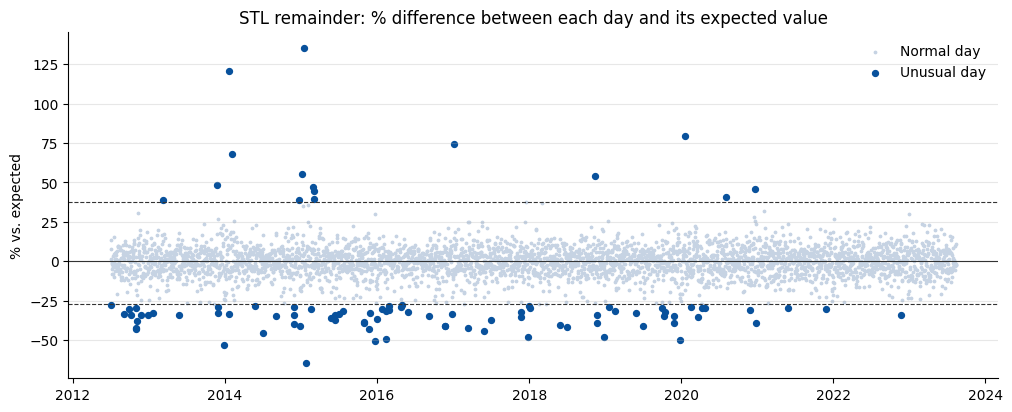

,crash_count,pct_vs_expected,weekday,likely_cause
date,,,,
2012-09-26,404,-30.0,Wednesday,Other / unexplained
2012-10-29,294,-43.0,Monday,Hurricane Sandy
2012-10-30,371,-30.0,Tuesday,Hurricane Sandy
2012-11-02,344,-42.0,Friday,Hurricane Sandy
2012-11-03,307,-38.0,Saturday,Hurricane Sandy
2013-03-08,850,39.0,Friday,"Winter, more crashes (likely snow/ice)"
2013-11-26,867,48.0,Tuesday,"Winter, more crashes (likely snow/ice)"
2014-01-21,1160,120.0,Tuesday,"Winter, more crashes (likely snow/ice)"
2014-02-03,957,68.0,Monday,"Winter, more crashes (likely snow/ice)"


In [ ]:
# STL on the full daily series: weekly pattern, month-scale trend
stl_full = STL(np.log(daily), period=7, seasonal=53, trend=31, robust=True).fit()
remainder = stl_full.resid

# Robust standard deviation: based on the median, so the outliers themselves don't inflate it
robust_sd = 1.4826 * (remainder - remainder.median()).abs().median()
threshold = 4 * robust_sd
print(f"Typical remainder size (robust std): {robust_sd:.3f} | threshold: ±{threshold:.3f}")
print(f"On the original scale: more than {(np.exp(threshold) - 1) * 100:.0f}% above "
      f"or {(1 - np.exp(-threshold)) * 100:.0f}% below the expected value")

unusual = pd.DataFrame({
    "crash_count": daily,
    "pct_vs_expected": ((np.exp(remainder) - 1) * 100).round(0),
})[remainder.abs() > threshold]
unusual["weekday"] = unusual.index.day_name()

# Holiday dates including the "observed" day off (e.g. Monday 26 Dec when Christmas falls on a Sunday)
all_holiday_dates = pd.DatetimeIndex(list(holidays.US(years=range(2012, 2024), observed=True).keys()))
thanksgiving = holiday_dates[holiday_dates == "Thanksgiving Day"].index
thanksgiving_weekend = thanksgiving.append([thanksgiving + pd.Timedelta(days=1), thanksgiving + pd.Timedelta(days=2)])

def likely_cause(date, pct):
    """Assign a likely cause to an unusual day, based on its date and direction."""
    if date in all_holiday_dates:
        return "Public holiday"
    if date in thanksgiving_weekend:
        return "Thanksgiving weekend"
    if pd.Timestamp("2012-10-29") <= date <= pd.Timestamp("2012-11-10"):
        return "Hurricane Sandy"
    if pd.Timestamp("2020-03-01") <= date <= pd.Timestamp("2020-06-30"):
        return "COVID-19 lockdown"
    if pct > 0 and date.month in [11, 12, 1, 2, 3]:
        return "Winter, more crashes (likely snow/ice)"
    if pct < 0 and date.month in [12, 1, 2, 3]:
        return "Winter, fewer crashes (likely major storm)"
    return "Other / unexplained"

unusual["likely_cause"] = [likely_cause(d, p) for d, p in zip(unusual.index, unusual["pct_vs_expected"])]

n_high = (unusual["pct_vs_expected"] > 0).sum()
print(f"\nUnusual days: {len(unusual)} ({n_high} high, {len(unusual) - n_high} low)\n")
print(unusual["likely_cause"].value_counts())

# Chart: remainder for every day, unusual days highlighted
pct_remainder = (np.exp(remainder) - 1) * 100
is_unusual = remainder.abs() > threshold
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.scatter(pct_remainder.index[~is_unusual], pct_remainder[~is_unusual], s=3, color="#C6D3E3", label="Normal day")
ax.scatter(pct_remainder.index[is_unusual], pct_remainder[is_unusual], s=18, color="#08519C", label="Unusual day")
for limit in [threshold, -threshold]:
    ax.axhline((np.exp(limit) - 1) * 100, color="#333333", linestyle="--", linewidth=0.8)
ax.axhline(0, color="#333333", linewidth=0.8)
ax.set_title("STL remainder: % difference between each day and its expected value")
ax.set_ylabel("% vs. expected")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False, loc="upper right")
plt.show()

# Every unusual day that isn't a holiday
unusual[~unusual["likely_cause"].isin(["Public holiday", "Thanksgiving weekend"])]

**What this shows**

95 days (2.3% of the series) differ from their expected value by more than about 38% upwards or 27% downwards. Most can be explained:

- **Public holidays and Thanksgiving weekend (55 days, the largest group).** These are almost all low days, confirming Section 5.1. The Friday and Saturday after Thanksgiving are also consistently low, even though they aren't federal holidays.
- **Winter days with more crashes (14 days).** The largest positive outliers all fall between November and March, e.g. 21 January 2014 (+120%) and 18 January 2015 (+136%). This pattern is consistent with snow and ice making roads dangerous while people still drive.
- **Winter days with fewer crashes (7 days).** For example 27 January 2015 (−64%), when New York banned road travel during a blizzard. Very severe storms seem to have the **opposite** effect: people stay home, so there are fewer crashes. Weather can push crashes either way, depending on whether people still travel.
- **Hurricane Sandy (4 days)**, at landfall on 29–30 October 2012 and in the days after.
- **The COVID-19 lockdown (only 3 days).** The lockdown is not mainly a single-day outlier: it's a **level shift**, which the month-scale trend absorbs (Section 3). Only the sharpest days around it stand out.
- **Other / unexplained (12 days).** Three of these match Jewish High Holy Days (26 September 2012 and 9 October 2019, Yom Kippur; 30 September 2019, Rosh Hashanah), which may reduce traffic in parts of NYC. 4 August 2020 (+41%) matches the date of a tropical storm that hit the city. The rest, such as 12–13 June 2015, have no clear cause and may reflect recording problems; they are few and isolated.

**Very few unusual days after 2021.** The chart shows almost no flagged days in 2021–2023 apart from Thanksgiving. Christmas, for example, is flagged every year before 2021 but not after. Holidays and weather may have a weaker effect on crashes now, which matches the flatter weekly pattern after COVID (Section 4.1).

**Implications**

1. **Holidays should be modelled**, not removed: they're the largest group of unusual days, they repeat every year, and they're known in advance.
2. **Weather explains many of the remaining outliers**, but in both directions. Adding weather data (snowfall, storm warnings) could help models, but it would have to be forecast itself, so it is only useful for short horizons.
3. **The unusual days should be kept in the data.** They are real events that will happen again, and removing them would make models look more accurate than they really are on future data.

### 5.3 Reporting changes

Some patterns in the data come from changes in **how** crashes were recorded rather than in how many happened. These were identified in the data cleaning notebook, which works with the individual crash records:

| Finding (cleaning notebook section) | What was found | How it was handled |
|---|---|---|
| Missing borough (4.4) | Borough missing for about 23–25% of crashes in 2012–2015, then 33–38% from 2016 | Forecast the **city-wide total**; borough-level series would show an artificial drop from 2016 |
| Injury categories (5.5) | Persons injured ≠ pedestrians + cyclists + motorists in 0.32% of crashes, clustered in 2016 and 2021–2023 | Not used for the target; if injuries were forecast, the persons total should be used |
| Reporting lag (5.3) | The last four days (15–18 August 2023) had only 53–80% of the normal count, because recent crashes had not yet been entered | **Trimmed**; the series ends on 14 August 2023 |
| Duplicate reports (3.3) | 1,710 crashes entered twice under different IDs | **Removed** (0.08% of rows) |

The borough and injury changes suggest the NYPD changed its recording practices around 2016 and again around 2021. The check below tests whether the 2016 change also affected the **total number** of crashes recorded. If it did, the target series itself would contain an artificial step.

If the count changed suddenly because of recording, the change compared with the same month a year earlier would jump at one point and stay raised for exactly 12 months.

Change vs. the same month a year earlier (%), by year:
      mean   min   max
date                  
2013   3.6  -2.2  11.9
2014   1.3  -4.5   9.2
2015   5.5  -3.4  13.0
2016   5.5  -1.8  12.2
2017   0.7  -3.9   4.0
2018   0.4  -2.6   3.3
2019  -8.5 -15.4   0.5


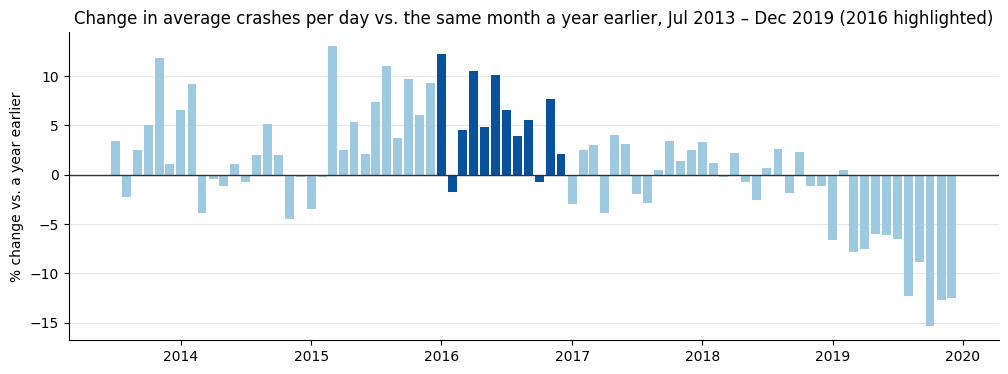

In [ ]:
# Average crashes per day by month, compared with the same month one year earlier
monthly_avg = daily[:"2023-07-31"].resample("MS").mean()
yoy_change = ((monthly_avg / monthly_avg.shift(12) - 1) * 100)["2013-07-01":"2019-12-01"]

print("Change vs. the same month a year earlier (%), by year:")
print(yoy_change.groupby(yoy_change.index.year).agg(["mean", "min", "max"]).round(1))

colors = ["#08519C" if date.year == 2016 else "#9ECAE1" for date in yoy_change.index]
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(yoy_change.index, yoy_change, width=25, color=colors)
ax.axhline(0, color="#333333", linewidth=1)
ax.set_title("Change in average crashes per day vs. the same month a year earlier, "
             "Jul 2013 – Dec 2019 (2016 highlighted)")
ax.set_ylabel("% change vs. a year earlier")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
plt.show()

**What this shows**

- **No sudden step in 2016.** Crashes grew by about 5.5% a year in both 2015 and 2016, and the growth was spread over both years rather than jumping at one point. A recording change that altered which crashes were counted would show as a sudden rise lasting exactly 12 months, and that pattern isn't visible. The 2016 change appears to have affected **which details** were recorded (such as borough), not **how many** crashes were recorded. The total count is therefore suitable as the target, although a gradual change can't be ruled out completely.
- **Crashes were already falling before COVID.** From mid-2019, every month was below the same month a year earlier, by up to 15% (−8.5% on average in 2019). The decline that continued after 2020 (Section 3.3) therefore began **before** the pandemic. The data doesn't show why, but it means the downward trend isn't only a COVID effect.

**Implications**

1. **The city-wide daily count is a reliable target.** The known recording changes affect details of the crash records but show no visible effect on the total number of crashes.
2. **Reporting lag matters if the forecasts are used in practice.** The most recent days in any new data download will be incomplete, as the last four days of this one were. A model run on fresh data should either leave out the latest few days or treat them as provisional.
3. **The downward trend since mid-2019 is likely to continue** in the near future. Models should be able to follow a gradually falling level rather than assume a constant one.

## 6. Autocorrelation and stationarity

Forecasting models use past values to predict future ones, so it matters how strongly each day is related to earlier days. This section looks at:
- **Autocorrelation (ACF):** the correlation between the series and itself shifted by a number of days (the "lag"). A high value at lag 7 means a day is similar to the same weekday one week earlier.
- **Partial autocorrelation (PACF):** the same, but with the effect of the in-between days removed. It shows which lags add information of their own.
- **Stationarity:** whether the series has a stable mean and variance over time. Many classical models (e.g. ARIMA) require a stationary series, so a non-stationary one has to be transformed first, usually by differencing.

Both are calculated on the post-COVID period (July 2020 to August 2023), the candidate training window from Section 3. On the full series, the 2020 break would dominate the results.

### 6.1 ACF and PACF

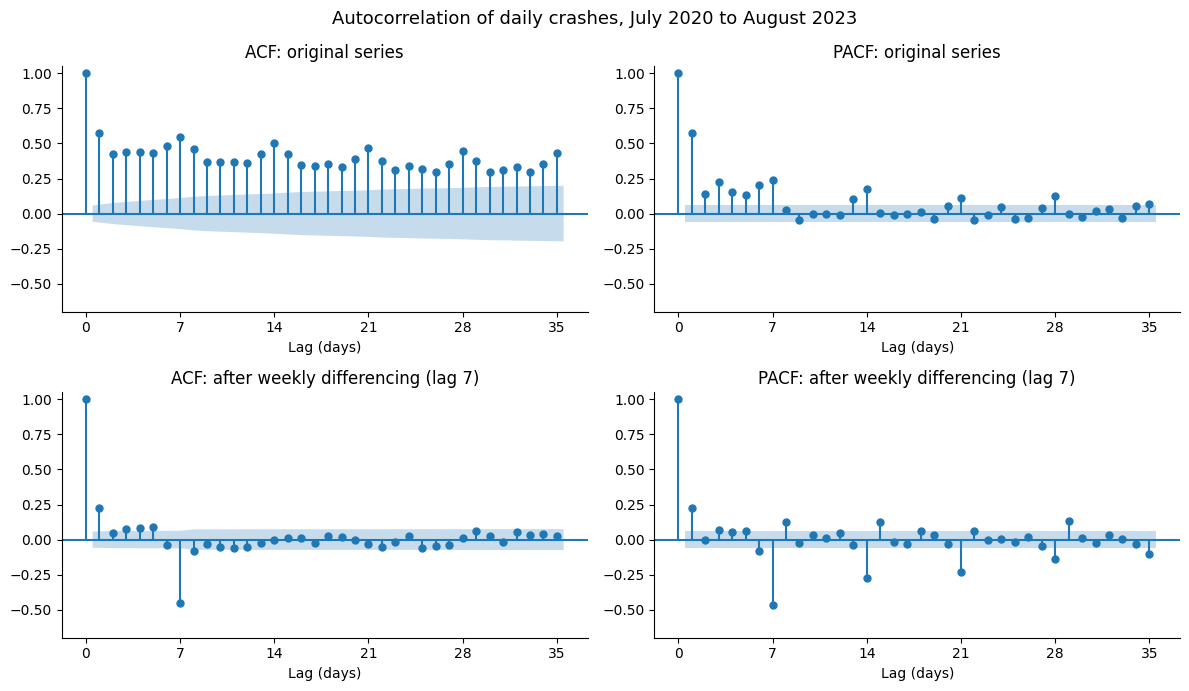

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Weekly differencing: each day minus the same weekday one week earlier
weekly_diff = POST_COVID.diff(7).dropna()

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
plot_acf(POST_COVID, lags=35, ax=axes[0, 0], title="ACF: original series")
plot_pacf(POST_COVID, lags=35, ax=axes[0, 1], title="PACF: original series", method="ywm")
plot_acf(weekly_diff, lags=35, ax=axes[1, 0], title="ACF: after weekly differencing (lag 7)")
plot_pacf(weekly_diff, lags=35, ax=axes[1, 1], title="PACF: after weekly differencing (lag 7)", method="ywm")

for ax in axes.flat:
    ax.set_xticks(range(0, 36, 7))     # tick marks at 0, 7, 14, ... so weekly lags are easy to spot
    ax.set_xlabel("Lag (days)")
    ax.set_ylim(-0.7, 1.05)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Autocorrelation of daily crashes, July 2020 to August 2023", fontsize=13)
fig.tight_layout()
plt.show()

**What this shows**

**Original series (top row):**
- The ACF stays high at every lag and decays very slowly. This is the typical sign of a **non-stationary** series: the level drifts (here, the downward trend from Section 3.3), so values far apart in time are still correlated.
- The spikes at lags 7, 14, 21, 28 and 35 confirm the **weekly seasonality** found in Section 4.1.

**After weekly differencing (bottom row):**
- Almost all of the autocorrelation disappears. What remains is a short-term link to the previous day (lag 1) and a strong **negative** spike at lag 7 in the ACF, with matching negative spikes at 7, 14, 21, 28 in the PACF that shrink with each week.
- This pattern (one negative ACF spike at the seasonal lag, decaying PACF spikes at multiples of it) is the classic signature of a **seasonal moving-average term**.

**Implication for model choice:** for a SARIMA model, these plots suggest weekly seasonal differencing (D = 1, period 7) with a seasonal MA(1) term, plus a small non-seasonal AR(1) or MA(1) term for the lag-1 link. A sensible starting point would be **SARIMA(1,0,0)(0,1,1)[7]** or **SARIMA(0,0,1)(0,1,1)[7]**, to be refined by comparing information criteria (AIC). For machine-learning models, the same plots suggest the most useful input features: the previous day (lag 1) and the same weekday in previous weeks (lags 7, 14, ...). Weekly differencing does not remove the **yearly** pattern from Section 4.2, so that would need separate terms (e.g. month indicators or Fourier terms).

### 6.2 Stationarity tests

Two tests are used because they work in opposite directions, so together they give a more reliable answer:
- **ADF (Augmented Dickey-Fuller):** assumes the series is **not** stationary. A p-value **below 0.05** is evidence that it **is** stationary.
- **KPSS:** assumes the series **is** stationary. A p-value **below 0.05** is evidence that it is **not**.

A series is treated as stationary only when both agree: ADF p < 0.05 **and** KPSS p > 0.05.

In [ ]:
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning

# KPSS only reports p-values between 0.01 and 0.10; values beyond that range trigger a warning
warnings.simplefilter("ignore", InterpolationWarning)

versions = {
    "Original": POST_COVID,
    "First difference": POST_COVID.diff(),
    "Weekly difference (lag 7)": POST_COVID.diff(7),
}

rows = []
for name, s in versions.items():
    s = s.dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    rows.append({
        "series": name,
        "ADF p-value": round(adf_p, 3),
        "KPSS p-value": round(kpss_p, 3),
        "stationary?": "Yes" if (adf_p < 0.05 and kpss_p > 0.05) else "No",
    })
pd.DataFrame(rows).set_index("series")


/tmp/ipykernel_12351/2730681980.py:17: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_p = adfuller(s, autolag="AIC")[1]
/tmp/ipykernel_12351/2730681980.py:18: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_p = kpss(s, regression="c", nlags="auto")[1]
/tmp/ipykernel_12351/2730681980.py:17: FutureWarning: adfuller currently retu

,ADF p-value,KPSS p-value,stationary?
series,,,
Original,0.09,0.01,No
First difference,0.00,0.10,Yes
Weekly difference (lag 7),0.00,0.10,Yes


## 7. Variance and transformation

Section 2 noted that day-to-day variation looked smaller after 2020, when the level was lower. If the spread of a series grows with its level, models that assume constant variance can fit badly, and a **log transformation** is the usual fix: it turns proportional changes into constant ones.

Here the series is split into calendar months. For each month we calculate the average daily level and the standard deviation (the spread) of the daily values, then check whether months with a higher level also have a larger spread, on both the raw and the log scale. The lockdown and recovery months (March to June 2020) are left out.

Months: 130
Correlation of monthly level with spread:
  raw counts: 0.82
  log counts: 0.43

                 mean     std  std_of_log
period                                   
After COVID   288.012  31.017       0.110
Before COVID  592.128  88.217       0.155

After COVID only, correlation of level with spread (raw): 0.09


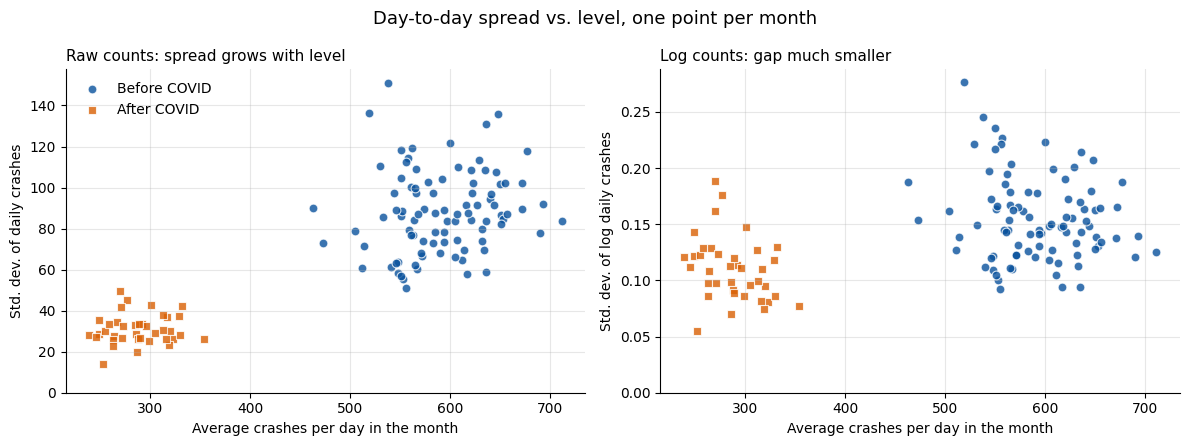

In [ ]:
import numpy as np

in_lockdown = (daily.index >= "2020-03-01") & (daily.index < "2020-07-01")
stable_days = daily[~in_lockdown]

# One row per month: level, spread of raw counts, spread of log counts
by_month = pd.DataFrame({
    "mean": stable_days.resample("MS").mean(),
    "std": stable_days.resample("MS").std(),
    "std_of_log": np.log(stable_days).resample("MS").std(),
}).dropna()
by_month["period"] = np.where(by_month.index < "2020-03-01", "Before COVID", "After COVID")

print("Months:", len(by_month))
print("Correlation of monthly level with spread:")
print("  raw counts:", round(by_month["mean"].corr(by_month["std"]), 2))
print("  log counts:", round(by_month["mean"].corr(by_month["std_of_log"]), 2))
print()
print(by_month.groupby("period")[["mean", "std", "std_of_log"]].mean().round(3))

post = by_month[by_month["period"] == "After COVID"]
print("\nAfter COVID only, correlation of level with spread (raw):", round(post["mean"].corr(post["std"]), 2))

# Scatter: one point per month, raw scale on the left, log scale on the right
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
styles = {"Before COVID": ("#08519C", "o"), "After COVID": ("#D95F02", "s")}
for ax, column, title in zip(axes, ["std", "std_of_log"],
                             ["Raw counts: spread grows with level", "Log counts: gap much smaller"]):
    for period, (color, marker) in styles.items():
        part = by_month[by_month["period"] == period]
        ax.scatter(part["mean"], part[column], color=color, marker=marker, s=40, alpha=0.8,
                   edgecolor="white", linewidth=0.8, label=period)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Average crashes per day in the month")
    ax.set_ylim(bottom=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Std. dev. of daily crashes")
axes[1].set_ylabel("Std. dev. of log daily crashes")
axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Day-to-day spread vs. level, one point per month", fontsize=13)
fig.tight_layout()
plt.show()

**What this shows**

- **Across the full history, the spread clearly grows with the level.** The correlation between a month's level and its spread is 0.82. Before COVID the level averaged 592 crashes a day with a typical spread of 88; after COVID, 288 with a spread of 31. The level halved, but the spread fell to about a third.
- **A log transformation reduces this link but doesn't remove it.** On the log scale the correlation drops to 0.43, and the gap between the two periods shrinks a lot (0.155 against 0.110), but pre-COVID months still vary more. Part of the remaining difference is probably the flatter weekly pattern after COVID (Section 4.1): with less difference between weekdays and weekends, there is less day-to-day variation within each month.
- **Within the post-COVID period, spread is unrelated to level** (correlation 0.09). Monthly levels after July 2020 only range from about 240 to 350 crashes a day, too narrow a range for the level to affect the spread much.

**Implications**

1. **If models are trained on post-COVID data only, a log transformation is not necessary**, because the variance is already roughly stable within that period. It can still be tried as an option, but it isn't required.
2. **If the full history is used, a log transformation is advisable**, but it won't fully solve the problem. Together with the changes in level, trend and weekly pattern (Sections 3 and 4), this is another reason the group may prefer the post-COVID window.
3. **For evaluation**, absolute errors from different periods aren't directly comparable: an error of 30 crashes is small at 600 a day but large at 250. Percentage-based metrics such as MAPE make results comparable across periods and frequencies. The post-COVID series never comes close to zero, so MAPE is well defined here. This is taken up in the validation strategy (Section 9).